# 2. Where should the fulfillment centers go?

**Goal of this notebook:** decide which cities should get a fulfillment center (FC), and measure what the network saves in freight and delivery time.

Notebook 1 showed the problem: 72% of items ship from São Paulo state, most of them travel far, and distance costs money and days. The idea tested here is to hold stock in a few regional FCs. Each item then makes two trips:

1. **Inbound:** seller to FC, in bulk on a truck with thousands of other items. Cheap per item.
2. **Outbound:** FC to customer, as a single parcel. Expensive per item, but now the trip is short.

A region only gets an FC if that beats shipping direct from the seller, which is how every order moves today.

**The steps**
0. Load one year of shipments.
1. Build a freight **rate card** from the data: what does a parcel cost, given distance and weight?
2. Price the bulk inbound trip.
3. Set up the demand points (cities) and the candidate FC sites.
4. Compute the cost of every option.
5. Write the decision as an **optimization model** in PuLP.
6. Check the solver against brute force.
7. Solve for 1 to 8 FCs and pick a network.
8. Stress-test the assumptions.

In [1]:
import sys
sys.path.insert(0, "../src")

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp

from helpers import COLORS, RESULTS, connect, haversine_km, run_query, save_figure, set_chart_style

set_chart_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
con = connect()

## Step 0. Load one year of shipments

The `shipments` query joins seven tables into one row per item sold: where it shipped from, where it went, its weight, the freight charged, the days it spent with the carrier and its product category.

In [2]:
ship = run_query("shipments", con)
con.close()

ship["dist_km"] = haversine_km(ship["seller_lat"], ship["seller_lng"], ship["cust_lat"], ship["cust_lng"])

print(f"{len(ship):,} items in {ship['order_id'].nunique():,} orders")
print(f"Total freight paid in the study year: R$ {ship['freight_value'].sum():,.0f}")
ship[["price", "freight_value", "weight_kg", "dist_km", "transit_days"]].describe().T

-- The base table for the network model (notebook 2): one row per item sold in
-- the study year, with where it shipped from, where it went, what it weighed
-- and what the freight cost. Seven tables joined into one.
SELECT
    oi.order_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_weight_g / 1000.0             AS weight_kg,
    c.customer_city,
    c.customer_state,
    cg.lat                                  AS cust_lat,
    cg.lng                                  AS cust_lng,
    s.seller_state,
    sg.lat                                  AS seller_lat,
    sg.lng                                  AS seller_lng,
    julianday(o.order_delivered_customer_date)
      - julianday(o.order_delivered_carrier_date) AS transit_days,
    o.order_purchase_timestamp              AS purchased_at,
    -- added for the simulation in notebook 6: what was bought, and how long
    -- the whole trip took from purchase to the customer's door
    COALESCE(t.product_category_name

84,523 items in 73,841 orders
Total freight paid in the study year: R$ 1,703,757


,count,mean,std,min,25%,50%,75%,max
price,"84,523.00",119.98,177.92,0.85,39.99,75.00,134.99,"6,729.00"
freight_value,"84,523.00",20.16,16.15,0.00,12.98,16.45,21.45,409.68
weight_kg,"84,523.00",2.03,3.62,0.00,0.28,0.65,1.75,40.42
dist_km,"84,523.00",586.87,582.68,0.00,167.79,425.01,780.51,"3,399.19"
transit_days,"84,515.00",9.28,8.55,0.00,3.97,7.04,12.08,205.19


`dist_km` is the straight-line distance between the seller's zip code and the customer's zip code (the haversine formula, in `src/helpers.py`). Real trucks drive on roads, so true distances are longer, but straight-line distance is a consistent yardstick for comparing options.

The average item weighs about 2 kg, costs about R\$20 to ship and travels about 590 km. Half of all items weigh under 0.65 kg, so a few heavy items pull the average weight up.

## Step 1. Build a freight rate card

To compare networks we need to predict what a parcel costs on a route nobody has shipped yet, for example from a new FC in Salvador to a customer nearby.

Carriers price parcels by **distance zone** and **weight**. So the model copies that structure. Split shipments into eight distance zones, and inside each zone fit a straight line:

$$\text{freight} = \text{base}_{zone} + \text{rate}_{zone} \times \text{weight in kg}$$

- `base` is the cost of moving any parcel in that zone, even a very light one (pickup, sorting, the delivery stop).
- `rate` is the extra cost per kg.

`np.polyfit(x, y, 1)` fits that line by least squares, the same method as linear regression in a statistics class.

In [3]:
ZONE_EDGES = [50, 100, 250, 500, 1000, 1500, 2000]          # km, upper edge of zones 0 to 6
ZONE_LABELS = ["0-50", "50-100", "100-250", "250-500", "500-1,000", "1,000-1,500", "1,500-2,000", "2,000+"]


def zone_of(dist_km):
    """Turn a distance in km into a zone number from 0 (local) to 7 (2,000+ km)."""
    return np.digitize(dist_km, ZONE_EDGES, right=True)


ship["zone"] = zone_of(ship["dist_km"])

rows = []
for zone, group in ship.groupby("zone"):
    rate, base = np.polyfit(group["weight_kg"], group["freight_value"], 1)   # slope, intercept
    transit = group.loc[group["transit_days"] > 0, "transit_days"]
    rows.append({
        "zone": zone,
        "distance_km": ZONE_LABELS[zone],
        "items": len(group),
        "avg_dist_km": group["dist_km"].mean(),
        "avg_freight": group["freight_value"].mean(),
        "base": base,
        "rate_per_kg": rate,
        "median_transit_days": transit.median(),
    })
rate_card = pd.DataFrame(rows).set_index("zone")
rate_card

,distance_km,items,avg_dist_km,avg_freight,base,rate_per_kg,median_transit_days
zone,,,,,,,
0,0-50,10776,21.28,11.44,8.35,1.65,1.80
1,50-100,5576,75.36,12.14,8.85,1.72,2.22
2,100-250,8409,165.94,15.81,11.06,1.97,4.95
3,250-500,24258,375.83,19.53,13.99,2.62,6.99
4,"500-1,000",22491,710.14,21.45,15.68,3.02,8.82
5,"1,000-1,500",5669,"1,236.32",26.84,19.14,3.72,11.88
6,"1,500-2,000",2670,"1,750.90",37.14,26.40,4.94,13.41
7,"2,000+",4674,"2,307.80",36.87,28.33,4.39,14.86


Read one row to check it makes sense. In the local zone (0 to 50 km) a parcel costs about R\$8 plus R\$1.65 per kg, and typically spends under 2 days with the carrier. In the 2,000+ km zone the same parcel costs about R\$28 plus R\$4.40 per kg and takes about 15 days.

**The key fact for this project is in the `base` column.** Even a local parcel costs about R\$8 before weight. That fixed cost is paid on every parcel no matter how short the trip is, so moving stock closer to the customer can never remove it.

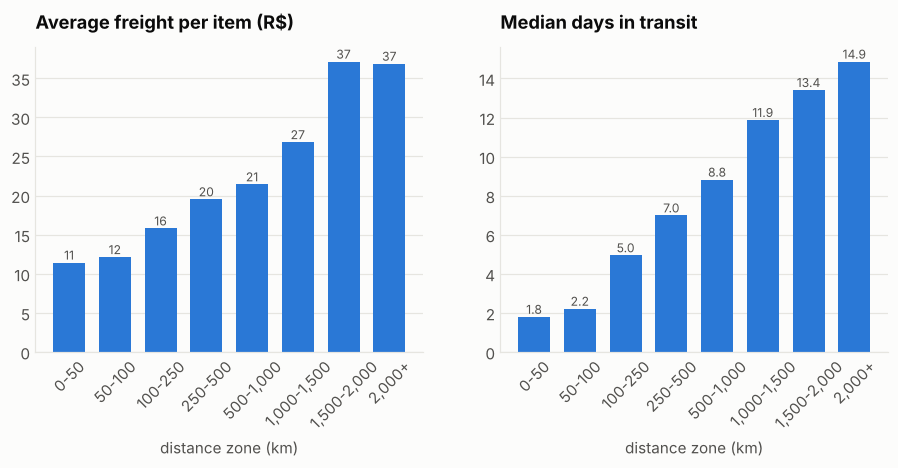

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, column, title, fmt in [
    (axes[0], "avg_freight", "Average freight per item (R$)", "{:.0f}"),
    (axes[1], "median_transit_days", "Median days in transit", "{:.1f}"),
]:
    bars = ax.bar(rate_card["distance_km"], rate_card[column], color=COLORS["blue"], width=0.7)
    for bar, value in zip(bars, rate_card[column]):
        ax.text(bar.get_x() + bar.get_width() / 2, value, fmt.format(value),
                ha="center", va="bottom", fontsize=8, color=COLORS["muted"])
    ax.set_title(title)
    ax.set_xlabel("distance zone (km)")
    ax.tick_params(axis="x", labelrotation=45)
    ax.grid(axis="x", visible=False)
save_figure(fig, "02_rate_card.png")
plt.show()

### How good is the rate card?

Predict the freight of every real shipment with the rate card and compare with what was actually charged. **R²** is the share of the variation in freight that the model explains (1.0 would be perfect).

In [5]:
BASE = rate_card["base"].to_numpy()               # BASE[zone]
RATE = rate_card["rate_per_kg"].to_numpy()        # RATE[zone]
TRANSIT = rate_card["median_transit_days"].to_numpy()


def parcel_cost(dist_km, weight_kg):
    """Rate-card freight for one parcel (works on arrays too)."""
    zone = zone_of(dist_km)
    return BASE[zone] + RATE[zone] * weight_kg


ship["predicted_freight"] = parcel_cost(ship["dist_km"], ship["weight_kg"])

residual = ship["freight_value"] - ship["predicted_freight"]
r_squared = 1 - (residual**2).sum() / ((ship["freight_value"] - ship["freight_value"].mean()) ** 2).sum()

print(f"R-squared: {r_squared:.2f}")
print(f"Actual total freight:    R$ {ship['freight_value'].sum():,.0f}")
print(f"Predicted total freight: R$ {ship['predicted_freight'].sum():,.0f}")
print(f"Typical miss on one parcel (mean absolute error): R$ {residual.abs().mean():.2f}")

R-squared: 0.57
Actual total freight:    R$ 1,703,757
Predicted total freight: R$ 1,703,757
Typical miss on one parcel (mean absolute error): R$ 5.20


The rate card explains a bit over half of the parcel-to-parcel variation. It misses things it cannot see, like bulky items, carrier choice and price changes. But the **total** matches the real total exactly, because a least-squares line always passes through the average of its data. Network design adds up tens of thousands of parcels, so the individual misses largely cancel. The model is weak for pricing one parcel and reasonable for comparing networks.

## Step 2. Price the inbound trip (seller to FC)

Inbound stock travels in bulk, so it does not pay the parcel rate. The model charges two things per item:

**A. Linehaul**, the truck trip, charged per kg per km. The rate card already tells us what long distance adds per kg: the `rate_per_kg` column climbs as distance grows. The slope of that climb is a linehaul rate in R\$ per kg per km.

Linehaul rate: R$ 0.00139 per kg per km  (R$ 1.39 per kg per 1,000 km)


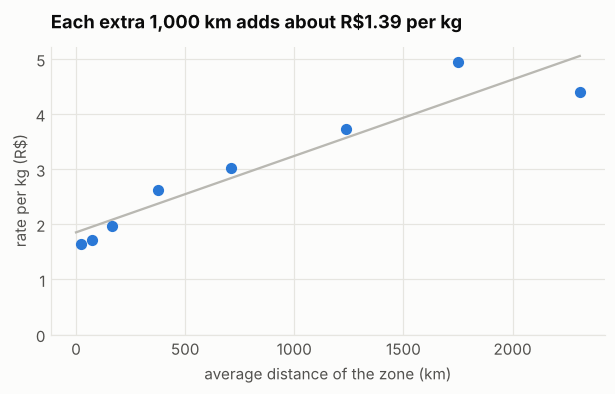

In [6]:
LINEHAUL_RATE, _ = np.polyfit(rate_card["avg_dist_km"], rate_card["rate_per_kg"], 1)
print(f"Linehaul rate: R$ {LINEHAUL_RATE:.5f} per kg per km  (R$ {LINEHAUL_RATE * 1000:.2f} per kg per 1,000 km)")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.scatter(rate_card["avg_dist_km"], rate_card["rate_per_kg"], color=COLORS["blue"], s=40, zorder=3)
xs = np.array([0, rate_card["avg_dist_km"].max()])
intercept = rate_card["rate_per_kg"].mean() - LINEHAUL_RATE * rate_card["avg_dist_km"].mean()
ax.plot(xs, intercept + LINEHAUL_RATE * xs, color=COLORS["gray"], linewidth=1.5, zorder=2)
ax.set_xlabel("average distance of the zone (km)")
ax.set_ylabel("rate per kg (R$)")
ax.set_ylim(0, None)
ax.set_title("Each extra 1,000 km adds about R$%.2f per kg" % (LINEHAUL_RATE * 1000))
plt.show()

This is the rate *parcel carriers* charge for distance. A full truck is cheaper per kg than a parcel network, so using this rate for bulk inbound **overstates** the inbound cost. That makes the savings estimate conservative.

**B. Handling**, a flat fee per item for the FC to receive it, shelve it, pick it and pack it. The data cannot tell us this number, because Olist had no FCs. **It is an assumption: R\$2.00 per item.** Step 8 tests what happens if the true number is anywhere from R\$0 to R\$6.

$$\text{inbound cost per item} = \text{R\$2.00} + \text{linehaul rate} \times \text{weight} \times \text{distance from seller to FC}$$

In [7]:
HANDLING_FEE = 2.00   # R$ per item through an FC. ASSUMPTION, stress-tested in step 8.

## Step 3. Demand points and candidate sites

**Demand points.** Modelling 74,000 separate orders is unnecessary. Customers in the same city are close together, so the model groups them by city. Each city becomes one demand point with a location, a number of items and a total weight.

In [8]:
ship["city_key"] = ship["customer_city"] + ", " + ship["customer_state"]

cities = (
    ship.groupby("city_key")
    .agg(
        state=("customer_state", "first"),
        lat=("cust_lat", "mean"),
        lng=("cust_lng", "mean"),
        items=("order_id", "size"),
        orders=("order_id", "nunique"),
        weight_kg=("weight_kg", "sum"),
    )
    .reset_index()
)
city_index = {key: i for i, key in enumerate(cities["city_key"])}
ship["city_i"] = ship["city_key"].map(city_index)          # which demand point each item belongs to

print(f"{len(cities):,} demand points (cities)")
cities.sort_values("items", ascending=False).head()

3,811 demand points (cities)


,city_key,state,lat,lng,items,orders,weight_kg
3312,"sao paulo, SP",SP,-23.57,-46.63,13853,11947,"25,385.23"
2891,"rio de janeiro, RJ",RJ,-22.92,-43.32,5690,4952,"12,647.42"
419,"belo horizonte, MG",MG,-19.91,-43.96,2431,2126,"4,924.38"
523,"brasilia, DF",DF,-15.81,-47.97,1721,1530,"2,923.47"
1065,"curitiba, PR",PR,-25.45,-49.28,1344,1158,"2,572.85"


**Candidate sites.** An FC could go anywhere, but the model needs a finite list to choose from. The list is the 50 cities with the most orders, plus the biggest city in every state so that every region has at least one option.

In [9]:
by_orders = cities.sort_values("orders", ascending=False)
candidates = (
    pd.concat([by_orders.head(50), by_orders.groupby("state").head(1)])
    .drop_duplicates("city_key")
    .reset_index(drop=True)
)
n_cities, n_sites = len(cities), len(candidates)
print(f"{n_sites} candidate sites in {candidates['state'].nunique()} states")

60 candidate sites in 27 states


## Step 4. The cost of every option

Before optimizing, compute what it costs to serve each city each possible way.

- `direct_cost[i]`: serve city *i* the way it is served today, every item as a parcel straight from its seller.
- `fc_cost[i, j]`: serve city *i* through an FC at site *j*. This is outbound parcels from the FC, plus handling, plus inbound linehaul from each seller to the FC.

In [10]:
items_per_city = cities["items"].to_numpy()
kg_per_city = cities["weight_kg"].to_numpy()

# --- direct: add up the rate-card cost of every item, by destination city
direct_cost = np.bincount(ship["city_i"], weights=ship["predicted_freight"], minlength=n_cities)

# --- outbound: distance from every city (rows) to every candidate site (columns)
dist_city_site = haversine_km(
    cities["lat"].to_numpy()[:, None], cities["lng"].to_numpy()[:, None],
    candidates["lat"].to_numpy()[None, :], candidates["lng"].to_numpy()[None, :],
)
zone_city_site = zone_of(dist_city_site)
outbound_cost = items_per_city[:, None] * BASE[zone_city_site] + kg_per_city[:, None] * RATE[zone_city_site]

# --- inbound linehaul: for each site, sum (weight x distance from seller to site) over the items of each city
kg_km_inbound = np.zeros((n_cities, n_sites))
for j in range(n_sites):
    seller_to_site = haversine_km(ship["seller_lat"], ship["seller_lng"], candidates.at[j, "lat"], candidates.at[j, "lng"])
    kg_km_inbound[:, j] = np.bincount(ship["city_i"], weights=ship["weight_kg"] * seller_to_site, minlength=n_cities)


def build_fc_cost(handling_fee=HANDLING_FEE, linehaul_rate=LINEHAUL_RATE):
    """Total cost of serving each city (row) through each candidate site (column)."""
    return outbound_cost + handling_fee * items_per_city[:, None] + linehaul_rate * kg_km_inbound


fc_cost = build_fc_cost()
BASELINE_COST = direct_cost.sum()

# typical transit days if every item ships direct, weighted by items
direct_transit = np.bincount(ship["city_i"], weights=TRANSIT[ship["zone"]], minlength=n_cities)
BASELINE_TRANSIT = direct_transit.sum() / items_per_city.sum()

print(f"Baseline (everything ships direct): R$ {BASELINE_COST:,.0f} a year, {BASELINE_TRANSIT:.2f} typical days in transit")

Baseline (everything ships direct): R$ 1,703,757 a year, 7.26 typical days in transit


A quick example makes the trade-off concrete. Take Salvador, the biggest city in the Northeast, and compare shipping direct with going through an FC in Salvador itself.

In [11]:
i = city_index["salvador, BA"]
j = candidates.index[candidates["city_key"] == "salvador, BA"][0]
n = items_per_city[i]
print(f"Salvador: {n:,} items a year")
print(f"  direct from sellers:        R$ {direct_cost[i] / n:5.2f} per item")
print(f"  via an FC in Salvador:      R$ {fc_cost[i, j] / n:5.2f} per item")
print(f"      outbound parcel         R$ {outbound_cost[i, j] / n:5.2f}")
print(f"      handling                R$ {HANDLING_FEE:5.2f}")
print(f"      inbound linehaul        R$ {LINEHAUL_RATE * kg_km_inbound[i, j] / n:5.2f}")

Salvador: 1,053 items a year
  direct from sellers:        R$ 28.36 per item
  via an FC in Salvador:      R$ 18.39 per item
      outbound parcel         R$ 12.01
      handling                R$  2.00
      inbound linehaul        R$  4.38


## Step 5. The optimization model

Now the decision itself. In words:

> Choose which sites to open, and how to serve each city (through one of the open FCs, or direct from sellers), so that total freight cost is as low as possible, when we are allowed to open exactly *p* sites.

**Decision variables**
- $y_j = 1$ if we open an FC at site $j$, otherwise 0. (Binary: a site is open or it is not.)
- $x_{ij}$ = the fraction of city $i$'s demand served through the FC at site $j$.
- $d_i$ = the fraction of city $i$'s demand that still ships direct from sellers.

**Objective** (minimize total yearly cost)

$$\min \sum_i \sum_j \text{fc\_cost}_{ij}\, x_{ij} \;+\; \sum_i \text{direct\_cost}_i\, d_i$$

**Constraints**
1. Every city is fully served: $\sum_j x_{ij} + d_i = 1$ for every city $i$.
2. A city can only use an FC that is open: $x_{ij} \le y_j$.
3. Open exactly $p$ sites: $\sum_j y_j = p$.

This is a classic operations research model called the **p-median problem**, with one twist: the "ship direct" option. Because some variables must be whole numbers (0 or 1), it is a **mixed-integer linear program**. With 60 candidates there are about 50 million ways to pick 6 sites, so trying them all is not practical. A solver finds the best one in seconds.

In [12]:
def solve_network(n_open, fc_cost, direct_cost):
    """Pick the n_open sites that minimize total cost. Returns the list of open site numbers."""
    n_cities, n_sites = fc_cost.shape

    # Shortcut: an FC route that costs more than shipping direct can never be chosen,
    # so leave it out. Same answer, much smaller model.
    useful = [(i, j) for i in range(n_cities) for j in range(n_sites) if fc_cost[i, j] < direct_cost[i]]
    sites_for_city = {}
    for i, j in useful:
        sites_for_city.setdefault(i, []).append(j)

    model = pulp.LpProblem("fulfillment_network", pulp.LpMinimize)

    # decision variables
    y = pulp.LpVariable.dicts("open", range(n_sites), cat="Binary")
    x = pulp.LpVariable.dicts("via_fc", useful, lowBound=0)
    d = pulp.LpVariable.dicts("direct", range(n_cities), lowBound=0)

    # objective: total yearly cost
    model += (
        pulp.lpSum(fc_cost[i, j] * x[i, j] for i, j in useful)
        + pulp.lpSum(direct_cost[i] * d[i] for i in range(n_cities))
    )

    # 1. every city is fully served
    for i in range(n_cities):
        model += pulp.lpSum(x[i, j] for j in sites_for_city.get(i, [])) + d[i] == 1

    # 2. a city can only use an FC that is open
    for i, j in useful:
        model += x[i, j] <= y[j]

    # 3. open exactly n_open sites
    model += pulp.lpSum(y.values()) == n_open

    model.solve(pulp.PULP_CBC_CMD(msg=False))
    assert pulp.LpStatus[model.status] == "Optimal"
    return [j for j in range(n_sites) if y[j].value() > 0.5]

Once the open sites are known, the rest is simple: each city uses whichever available option is cheapest. `evaluate_network` does that with plain NumPy and reports the cost, the typical transit time and the share of items that flow through FCs.

In [13]:
def evaluate_network(open_sites, fc_cost, direct_cost):
    """Cost and service of a network, given the list of open sites."""
    open_sites = list(open_sites)
    cost_via_open = fc_cost[:, open_sites]
    best_fc = cost_via_open.argmin(axis=1)                      # cheapest open FC for each city
    best_fc_cost = cost_via_open.min(axis=1)
    use_fc = best_fc_cost < direct_cost                         # otherwise the city keeps shipping direct
    assigned_site = np.where(use_fc, np.array(open_sites)[best_fc], -1)

    total_cost = np.where(use_fc, best_fc_cost, direct_cost).sum()
    fc_transit = items_per_city * TRANSIT[zone_city_site[np.arange(len(direct_cost)), assigned_site]]
    transit_days = np.where(use_fc, fc_transit, direct_transit).sum() / items_per_city.sum()
    return {
        "cost": total_cost,
        "saving": direct_cost.sum() - total_cost,
        "saving_pct": 100 * (1 - total_cost / direct_cost.sum()),
        "transit_days": transit_days,
        "pct_items_via_fc": 100 * items_per_city[use_fc].sum() / items_per_city.sum(),
        "assigned_site": assigned_site,
    }

## Step 6. Check the solver against brute force

A model can be wrong without crashing, so it is worth checking against something simple. For 1 site there are 60 options and for 2 sites there are 1,770 pairs. That is small enough to try **every** option and keep the cheapest. If the solver is set up correctly it must find the same answers.

In [14]:
def network_cost(sites):
    """Total cost if exactly these sites are open: every city takes its cheapest option."""
    cheapest_fc = fc_cost[:, list(sites)].min(axis=1)
    return np.minimum(cheapest_fc, direct_cost).sum()


def brute_force(n_open):
    """Try every possible set of n_open sites and return the cheapest one."""
    return sorted(min(combinations(range(n_sites), n_open), key=network_cost))


for n_open in (1, 2):
    solver_sites = sorted(solve_network(n_open, fc_cost, direct_cost))
    brute_sites = brute_force(n_open)
    names = ", ".join(candidates.loc[solver_sites, "city_key"])
    print(f"{n_open} site(s): solver = brute force? {solver_sites == brute_sites}   ->  {names}")

1 site(s): solver = brute force? True   ->  salvador, BA


2 site(s): solver = brute force? True   ->  salvador, BA, nova iguacu, RJ


The solver and brute force agree, so the model is doing what it is supposed to.

## Step 7. Solve for 1 to 8 fulfillment centers

In [15]:
results = []
networks = {}
for n_open in range(1, 9):
    sites = solve_network(n_open, fc_cost, direct_cost)
    outcome = evaluate_network(sites, fc_cost, direct_cost)
    networks[n_open] = sites
    results.append({
        "fcs": n_open,
        "total_cost": outcome["cost"],
        "saving": outcome["saving"],
        "saving_pct": outcome["saving_pct"],
        "transit_days": outcome["transit_days"],
        "pct_items_via_fc": outcome["pct_items_via_fc"],
        "sites": "; ".join(candidates.loc[sites, "city_key"]),
    })

summary = pd.DataFrame(results).set_index("fcs")
summary["added_saving"] = summary["saving"].diff().fillna(summary["saving"])       # what the newest FC adds
summary["added_saving_pct"] = summary["saving_pct"].diff().fillna(summary["saving_pct"])
pd.set_option("display.max_colwidth", 200)
summary[["saving", "saving_pct", "added_saving", "added_saving_pct", "transit_days", "pct_items_via_fc"]]

,saving,saving_pct,added_saving,added_saving_pct,transit_days,pct_items_via_fc
fcs,,,,,,
1,"55,110.51",3.23,"55,110.51",3.23,6.76,8.76
2,"106,387.24",6.24,"51,276.73",3.01,6.05,23.56
3,"136,104.09",7.99,"29,716.85",1.74,5.18,57.65
4,"160,643.89",9.43,"24,539.81",1.44,4.83,64.85
5,"181,179.59",10.63,"20,535.70",1.21,4.53,69.70
6,"200,224.14",11.75,"19,044.55",1.12,4.27,74.49
7,"215,561.63",12.65,"15,337.49",0.90,4.12,75.30
8,"228,904.73",13.44,"13,343.11",0.78,3.92,80.62


In [16]:
for n_open, row in summary.iterrows():
    print(n_open, "->", row["sites"])

1 -> salvador, BA
2 -> salvador, BA; nova iguacu, RJ
3 -> salvador, BA; osasco, SP; nova iguacu, RJ
4 -> salvador, BA; osasco, SP; nova iguacu, RJ; contagem, MG
5 -> porto alegre, RS; salvador, BA; osasco, SP; nova iguacu, RJ; contagem, MG
6 -> brasilia, DF; porto alegre, RS; salvador, BA; osasco, SP; nova iguacu, RJ; contagem, MG
7 -> brasilia, DF; porto alegre, RS; salvador, BA; osasco, SP; nova iguacu, RJ; contagem, MG; teresina, PI
8 -> brasilia, DF; curitiba, PR; porto alegre, RS; salvador, BA; osasco, SP; nova iguacu, RJ; contagem, MG; teresina, PI


**How to read this.**
- `saving_pct` is the cut in yearly freight compared with today.
- `added_saving` is what the newest FC contributes. Each new FC adds less than the one before it (diminishing returns), because the best locations are taken first.
- `transit_days` is the typical time a parcel spends with the carrier.

The sites the model picks line up with Brazil's biggest metro areas: Salvador, Rio de Janeiro (Nova Iguaçu), São Paulo (Osasco), Belo Horizonte (Contagem), Porto Alegre and Brasília. Nobody told the model these are major cities. It found them from order volumes and distances, which is a good sign the model behaves sensibly.

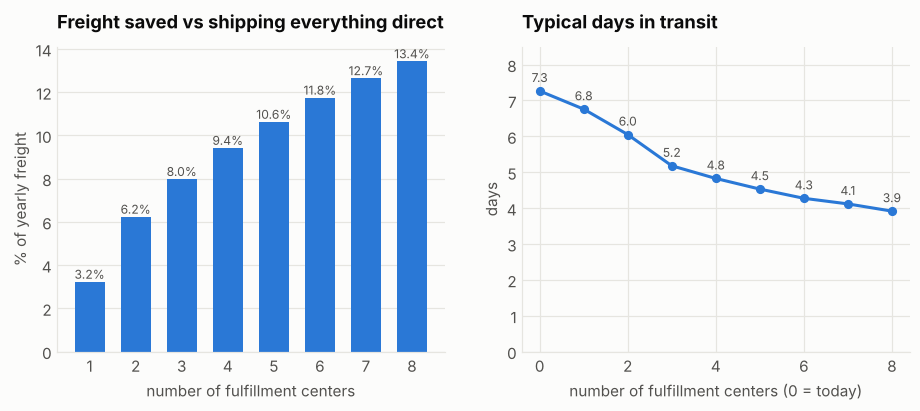

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

bars = axes[0].bar(summary.index, summary["saving_pct"], color=COLORS["blue"], width=0.65)
for bar, value in zip(bars, summary["saving_pct"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value, f"{value:.1f}%",
                 ha="center", va="bottom", fontsize=8, color=COLORS["muted"])
axes[0].set_title("Freight saved vs shipping everything direct")
axes[0].set_xlabel("number of fulfillment centers")
axes[0].set_xticks(list(summary.index))
axes[0].set_ylabel("% of yearly freight")
axes[0].grid(axis="x", visible=False)

transit_curve = [BASELINE_TRANSIT] + list(summary["transit_days"])
axes[1].plot(range(0, 9), transit_curve, color=COLORS["blue"], marker="o", markersize=5)
for n_open, value in enumerate(transit_curve):
    axes[1].text(n_open, value + 0.25, f"{value:.1f}", ha="center", fontsize=8, color=COLORS["muted"])
axes[1].set_ylim(0, 8.5)
axes[1].set_title("Typical days in transit")
axes[1].set_xlabel("number of fulfillment centers (0 = today)")
axes[1].set_ylabel("days")

save_figure(fig, "02_savings_by_network_size.png")
plt.show()

### Picking a network

The model minimizes freight for a given number of FCs, but it does not know what an FC costs to run (rent, staff, equipment). That number is not in the data, so instead of inventing one, read the table the other way around: **`added_saving` is the most an FC could cost per year and still pay for itself.**

The rule used here: keep adding FCs while the next one cuts yearly freight by at least 1 percentage point.

In [18]:
MIN_ADDED_SAVING_PCT = 1.0
worth_it = summary["added_saving_pct"] >= MIN_ADDED_SAVING_PCT
N_FCS = int(worth_it.cumprod().sum())           # count FCs until the first one that fails the rule

chosen_sites = networks[N_FCS]
chosen = evaluate_network(chosen_sites, fc_cost, direct_cost)

print(f"Chosen network: {N_FCS} fulfillment centers")
print(f"  yearly freight:   R$ {BASELINE_COST:,.0f}  ->  R$ {chosen['cost']:,.0f}")
print(f"  saving:           R$ {chosen['saving']:,.0f} a year ({chosen['saving_pct']:.1f}%)")
print(f"  typical transit:  {BASELINE_TRANSIT:.1f} days  ->  {chosen['transit_days']:.1f} days "
      f"({100 * (1 - chosen['transit_days'] / BASELINE_TRANSIT):.0f}% faster)")
print(f"  items through an FC: {chosen['pct_items_via_fc']:.0f}%  (the rest keep shipping direct)")

Chosen network: 6 fulfillment centers
  yearly freight:   R$ 1,703,757  ->  R$ 1,503,533
  saving:           R$ 200,224 a year (11.8%)
  typical transit:  7.3 days  ->  4.3 days (41% faster)
  items through an FC: 74%  (the rest keep shipping direct)


What each FC in the chosen network handles:

In [19]:
cities["served_by"] = [
    candidates.at[site, "city_key"] if site >= 0 else "direct from seller"
    for site in chosen["assigned_site"]
]
fc_table = (
    cities.groupby("served_by")
    .agg(cities=("city_key", "size"), items=("items", "sum"), weight_kg=("weight_kg", "sum"))
    .sort_values("items", ascending=False)
)
fc_table["pct_of_items"] = 100 * fc_table["items"] / fc_table["items"].sum()
fc_table

,cities,items,weight_kg,pct_of_items
served_by,,,,
"osasco, SP",208,28810,"55,725.89",34.09
direct from seller,1619,21565,"45,510.86",25.51
"nova iguacu, RJ",221,12288,"26,742.31",14.54
"salvador, BA",768,6795,"13,389.91",8.04
"contagem, MG",347,6205,"12,908.39",7.34
"brasilia, DF",373,4698,"9,218.74",5.56
"porto alegre, RS",275,4162,"8,342.03",4.92


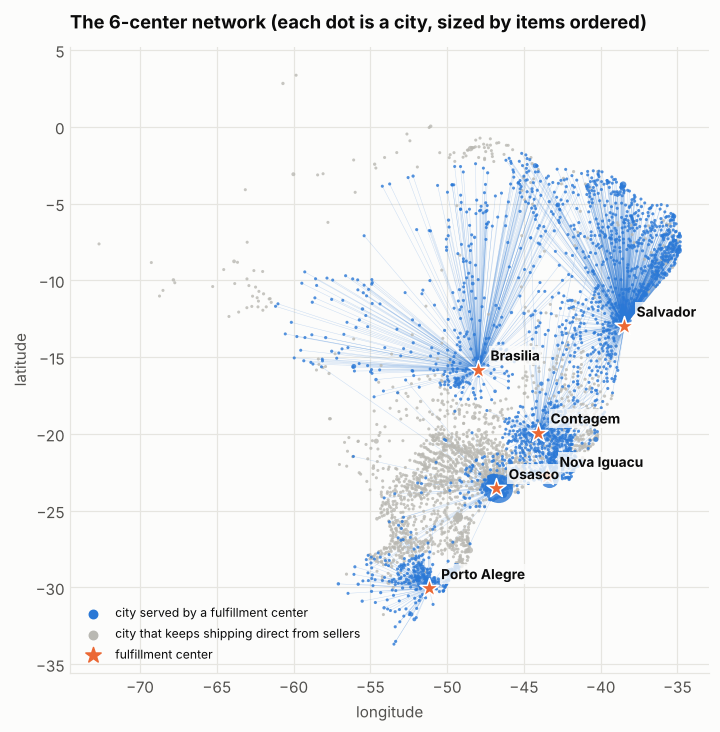

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))

direct = cities[cities["served_by"] == "direct from seller"]
via_fc = cities[cities["served_by"] != "direct from seller"]

# a thin line from each city to the FC that serves it
for site in chosen_sites:
    fc = candidates.loc[site]
    served = via_fc[via_fc["served_by"] == fc["city_key"]]
    for lat, lng in zip(served["lat"], served["lng"]):
        ax.plot([fc["lng"], lng], [fc["lat"], lat], color=COLORS["blue"], linewidth=0.3, alpha=0.25, zorder=1)

ax.scatter(direct["lng"], direct["lat"], s=4 + direct["items"] / 40, color=COLORS["gray"],
           alpha=0.8, linewidth=0, zorder=2)
ax.scatter(via_fc["lng"], via_fc["lat"], s=4 + via_fc["items"] / 40, color=COLORS["blue"],
           alpha=0.8, linewidth=0, zorder=3)
fcs = candidates.loc[chosen_sites]
ax.scatter(fcs["lng"], fcs["lat"], s=170, marker="*", color=COLORS["orange"],
           edgecolor="white", linewidth=1, zorder=5)
# empty plots, only there to give the legend three same-sized markers
ax.scatter([], [], s=30, color=COLORS["blue"], label="city served by a fulfillment center")
ax.scatter([], [], s=30, color=COLORS["gray"], label="city that keeps shipping direct from sellers")
ax.scatter([], [], s=110, marker="*", color=COLORS["orange"], label="fulfillment center")
for _, fc in fcs.iterrows():
    ax.annotate(fc["city_key"].split(",")[0].title(), (fc["lng"], fc["lat"]), xytext=(8, 6),
                textcoords="offset points", fontsize=9, fontweight="bold", zorder=6,
                bbox=dict(facecolor=COLORS["surface"], edgecolor="none", alpha=0.8, pad=1))

ax.set_aspect("equal")
ax.set_title(f"The {N_FCS}-center network (each dot is a city, sized by items ordered)")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.legend(loc="lower left", fontsize=8)
save_figure(fig, "02_network_map.png")
plt.show()

Each dot is a city, and together they trace the shape of Brazil. Blue cities are served from the starred FC they are connected to. Gray cities keep shipping direct. Most of them sit in the interior of São Paulo state and the neighboring southern states, close to the sellers already, so the extra handling step would cost more than it saves. A few are remote cities in the far North and West that are a long way from every FC.

## Step 8. Stress-test the assumptions

Two inputs to this model are uncertain: the handling fee (assumed) and the linehaul rate (estimated from parcel prices, and probably too high for trucks). A result that flips when an assumption moves a little is not worth much. So re-solve the model with each assumption changed and see what happens.

In [21]:
def rerun(handling_fee=HANDLING_FEE, linehaul_rate=LINEHAUL_RATE):
    cost = build_fc_cost(handling_fee, linehaul_rate)
    sites = solve_network(N_FCS, cost, direct_cost)
    out = evaluate_network(sites, cost, direct_cost)
    return {
        "saving_pct": out["saving_pct"],
        "saving": out["saving"],
        "transit_days": out["transit_days"],
        "pct_items_via_fc": out["pct_items_via_fc"],
        "same_sites_as_base_case": sorted(sites) == sorted(chosen_sites),
    }


handling_test = pd.DataFrame(
    {f"R$ {fee:.0f}": rerun(handling_fee=fee) for fee in [0, 1, 2, 3, 4, 5, 6]}
).T
handling_test.index.name = "handling fee per item"
handling_test

,saving_pct,saving,transit_days,pct_items_via_fc,same_sites_as_base_case
handling fee per item,,,,,
R$ 0,19.70,"335,571.12",4.14,85.47,True
R$ 1,15.60,"265,709.69",4.19,80.15,True
R$ 2,11.75,"200,224.14",4.27,74.49,True
R$ 3,8.94,"152,279.95",5.04,39.14,False
R$ 4,7.13,"121,496.71",5.21,32.77,False
R$ 5,5.57,"94,903.15",5.30,30.26,False
R$ 6,4.34,"73,893.91",5.61,22.79,False


In [22]:
linehaul_test = pd.DataFrame(
    {f"{mult:g}x": rerun(linehaul_rate=LINEHAUL_RATE * mult) for mult in [0.25, 0.5, 1, 1.5, 2]}
).T
linehaul_test.index.name = "linehaul rate vs base case"
linehaul_test

,saving_pct,saving,transit_days,pct_items_via_fc,same_sites_as_base_case
linehaul rate vs base case,,,,,
0.25x,15.77,"268,739.10",4.20,78.45,False
0.5x,14.41,"245,430.44",4.22,77.38,False
1x,11.75,"200,224.14",4.27,74.49,True
1.5x,9.30,"158,488.95",4.37,70.64,True
2x,7.06,"120,304.01",4.51,65.41,True


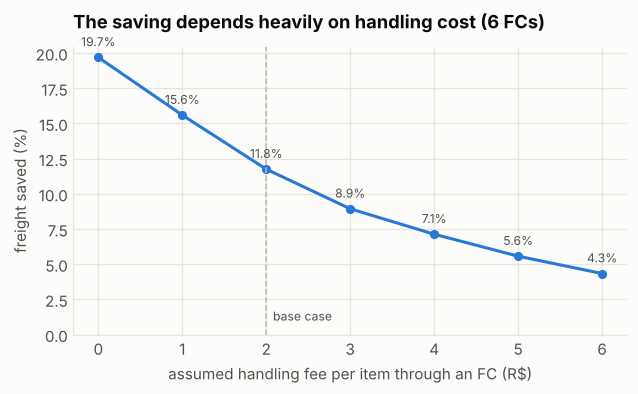

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
fees = [0, 1, 2, 3, 4, 5, 6]
ax.plot(fees, handling_test["saving_pct"].astype(float), color=COLORS["blue"], marker="o", markersize=5)
for fee, value in zip(fees, handling_test["saving_pct"].astype(float)):
    ax.text(fee, value + 0.8, f"{value:.1f}%", ha="center", fontsize=8, color=COLORS["muted"])
ax.axvline(HANDLING_FEE, color=COLORS["gray"], linewidth=1, linestyle="--")
ax.text(HANDLING_FEE + 0.08, 1.0, "base case", fontsize=8, color=COLORS["muted"])
ax.set_ylim(0, None)
ax.set_xlabel("assumed handling fee per item through an FC (R$)")
ax.set_ylabel("freight saved (%)")
ax.set_title(f"The saving depends heavily on handling cost ({N_FCS} FCs)")
save_figure(fig, "02_sensitivity_handling_fee.png")
plt.show()

**What the stress test says.**

- **Handling cost is the assumption that matters most.** At R\$0 per item the network saves about 20% of freight. At the assumed R\$2 it saves about 12%. At R\$6 it saves about 4%. From R\$3 upward the best set of sites changes and far fewer items go through FCs, because an FC only pays in regions far from the sellers.
- **The linehaul rate matters too, but less.** At half the base rate the saving rises to about 14%, and at double it falls to about 7%. Real truck rates are probably below the base rate, which would push the saving up.
- **The saving never turns negative**, because any city where an FC does not pay simply keeps shipping direct.
- **Transit time is more robust than cost.** It stays between about 4 and 5.6 days in every case tested, compared with 7.3 days today.

So the honest summary is a range, not a single number: with handling between R\$1 and R\$3 per item, a 6-center network cuts freight by roughly 9% to 16%.

## Save the results

Notebook 3 needs to know which FC serves which city, so it can size the inventory.

In [24]:
RESULTS.mkdir(exist_ok=True)

rate_card.to_csv(RESULTS / "rate_card.csv")
summary.to_csv(RESULTS / "network_by_number_of_fcs.csv")
cities[["city_key", "state", "lat", "lng", "items", "orders", "weight_kg", "served_by"]].to_csv(
    RESULTS / "city_assignments.csv", index=False
)
handling_test.to_csv(RESULTS / "sensitivity_handling_fee.csv")
linehaul_test.to_csv(RESULTS / "sensitivity_linehaul_rate.csv")
print("Saved 5 files to results/")

Saved 5 files to results/


## What we learned

1. **Six regional FCs cut freight by about 12% and typical transit time by about 41%** in the base case (R\$200,000 a year on R\$1.7 million of freight, and 7.3 days down to 4.3).
2. **Speed is the bigger win.** Freight falls by a modest amount because every parcel pays a fixed charge of about R\$8 no matter how short the trip, and an FC adds a handling step. Transit time falls a lot, because a local parcel takes about 2 days and a cross-country parcel takes about 2 weeks. Notebook 1 showed that late and slow orders get far worse reviews.
3. **Not every region should get an FC.** Many cities close to the sellers are better left alone. A model that forces every item through an FC actually costs more than today.
4. **The first two FCs do most of the work.** Salvador and Rio de Janeiro deliver about half of the total saving.

## Limits of this model

Be upfront about these in any conversation about the project.

- **Handling cost is assumed**, and the result is sensitive to it (step 8).
- **FC fixed costs are not included.** The `added_saving` column gives the most each FC could cost per year and still pay for itself.
- **Distances are straight lines**, not road distances.
- **No capacity limits.** Any FC can handle any volume.
- **The rate card explains about half the variation in parcel prices.** It is reasonable for totals, weak for single parcels.
- **The dataset is a sample of Olist's orders**, so the R\$ totals describe the sample. The percentages are the transferable result.
- **Holding stock in FCs costs money too.** That is the subject of notebook 3.